# Hipótesis 3 · Actividad, especie y desenlace
**Jordi Callejo · Proyecto de Ironhack · Revisión del 24 de octubre de 2026**

**Hipótesis:** Los incidentes con diferentes desenlaces presentan distribuciones distintas de actividades y especies identificadas.

**Pregunta de investigación:** ¿Qué diferencias encontramos entre los registros mortales y no mortales según la actividad realizada y la especie identificada?

Se estudia la **composición de los registros mortales y no mortales**. El análisis es observacional: las diferencias describen la base histórica disponible y no permiten estimar el riesgo de practicar una actividad o encontrarse con una especie.

## 1. Fuente, alcance y ejecución
Se usa `GSAF5.xls`, el Excel disponible junto al cuaderno. Se muestran su tamaño y huella para identificar la versión. No se dispone aquí de `GSAF5_limpio.xls` ni de `GSAF_limpio_local.csv`, usados por otros miembros del grupo. La integración final exige una base común, filtros acordados y volver a ejecutar los cuatro análisis.

**Decisiones:**
- Conservar todas las filas y columnas originales. Los nombres de columna se normalizan en una copia de trabajo.
- Aceptar solo Y y N tras normalizar espacios y mayúsculas. El resto es UNKNOWN. No deducir el desenlace de `Injury`.
- Usar todas las filas en el análisis principal y comprobar la sensibilidad al excluir `Type = Invalid`.
- Agrupar actividades en contextos amplios cercanos a la hipótesis 4, con reglas revisadas y auditables. La clasificación de especies es deliberadamente conservadora.
- Contar **filas documentadas**, no personas ni muertes individuales. No eliminar posibles duplicados sin contrastar sus fuentes.

**Para ejecutar:** abrir junto al Excel y ejecutar todas las celdas en orden. Dependencias: `pandas`, `numpy`, `matplotlib`, `scipy`, `xlrd`, `IPython`. Este cuaderno no instala paquetes, exporta archivos ni modifica el Excel. Para otra base, cambiar `DATA_PATH`, seleccionar el lector adecuado y revisar el esquema.

### Cómo leer los porcentajes
1. **Dentro de cada desenlace:** qué porcentaje de N o Y corresponde a cada actividad/especie. Cada columna suma 100 %. Es la comparación principal.
2. **Dentro de cada grupo:** Y / (Y + N) × 100. Se muestra como complemento y excluye UNKNOWN del denominador. No equivale al riesgo de muerte de una persona expuesta.

In [1]:
from pathlib import Path
import hashlib
import re
import unicodedata
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown

DATA_PATH = Path('GSAF5.xls')
MIN_SPECIES_N = 30  # Umbral descriptivo, no garantía de validez del contraste.
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
source = pd.read_excel(DATA_PATH, engine='xlrd')
raw = source.copy(deep=True)
raw.columns = raw.columns.str.strip()
if not raw.columns.is_unique:
    raise ValueError('Normalizar nombres ha creado columnas duplicadas')
required = {'Activity', 'Fatal Y/N', 'Species', 'Injury', 'Type', 'Year'}
if not required.issubset(raw.columns):
    raise ValueError(f'Faltan columnas: {required - set(raw.columns)}')
print(f'Fuente: {DATA_PATH.name}. Filas: {len(raw):,}. Columnas: {len(raw.columns)}.')
print(f'SHA-256: {source_hash}')
print(f'Python {sys.version.split()[0]}; pandas {pd.__version__}; numpy {np.__version__}; '
      f'matplotlib {matplotlib.__version__}; scipy {scipy.__version__}')
plt.rcParams.update({'figure.dpi':120, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False})
COLORS = {'N':'#287b9b', 'Y':'#c66b41', 'UNKNOWN':'#9a9fa8'}
LABELS = {'N':'No mortal (N)', 'Y':'Mortal (Y)', 'UNKNOWN':'Desconocido'}
def num(x):
    return f'{int(x):,}'.replace(',', '.')
def dec(x, digits=1):
    return f'{x:.{digits}f}'.replace('.', ',')

Fuente: GSAF5.xls. Filas: 7,125. Columnas: 23.
SHA-256: d94dc9774b23a0f65b185439e573c92c87ce3092b343b9c6c3cabdd5984cf443
Python 3.14.7; pandas 3.0.6; numpy 2.5.4; matplotlib 3.11.2; scipy 1.18.1


## 2. Limpieza y clasificación
### Actividad
Se normalizan Unicode, espacios y erratas explícitas documentadas en el código. Las reglas utilizan palabras o raíces delimitadas: `row` ya no coincide con *drowning* y `div` no coincide con *Maldivians* o *individual*. Se reconocen explícitamente *freediving* y *skindiving*.

Se conserva la prioridad **pesca submarina → naufragio/caída → pesca → buceo → surf/tablas → natación/baño → embarcaciones** para asignar un único contexto. Pesca requiere una actividad como *fishing* o *angling*: mencionar un pez no basta. El naufragio es un contexto, aunque el texto también diga que la persona nadaba. Si coinciden varios grupos, se marca el caso y se comprueba la sensibilidad al retirarlo. *Boarding a ship* se reconoce como embarcación, no como tabla. *Paddling* sin tabla explícita no se asigna a surf; si menciona canoa se reconoce embarcación. La prioridad es una decisión analítica, no una reconstrucción exacta del suceso.

“Otras / desconocida” reúne ausentes y actividades no clasificadas. Se muestra en las tablas, pero se excluye del contraste principal de actividad.

### Especie
Son **grupos de atribuciones textuales**, no identificaciones biológicas verificadas. Se excluyen dudas explícitas, alternativas, negaciones, referencias de proximidad y coincidencias de varios grupos. Un dato fuera del diccionario también queda sin identificar.

*Blacktip reef shark* se trata como Arrecife, evitando una coincidencia doble. *Oceanic whitetip* y `longimanus` se asignan a Oceánico punta blanca. *Whitetip* sin calificativo queda sin identificar por falta de precisión. Los grupos son amplios: “Cobrizo / whaler” no implica que todas sus descripciones identifiquen una misma especie.

In [2]:
def normalize(value):
    if pd.isna(value):
        return ''
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(value))).strip().casefold()

ACTIVITIES = [
    ('Pesca submarina', r'spear'),
    ('Naufragio / caída al agua', r'disaster|wreck|overboard|capsiz|sank|sunk|aircraft|torpedo'),
    ('Pesca', r'fish'),
    ('Buceo', r'div|snorkel|scuba'),
    ('Surf y tablas', r'surf|board|paddle|kite'),
    ('Natación y baño', r'swim|bath|wad|stand|float|tread|walk|play'),
    ('Embarcaciones', r'kayak|canoe|row|boat|sail'),
]
SPECIES = [
    ('Oceánico punta blanca', r'oceanic white|longimanus'),
    ('Arrecife', r'reef|whitetip'),
    ('Sand tiger / grey nurse', r'sand ?tiger|grey nurse|gray nurse|ragged ?tooth|sand ?shark'),
    ('Blanco', r'white shar|great white|white pointer|\bgws\b|carcharodon'),
    ('Tigre', r'tiger'), ('Toro', r'\bbull\b|zambesi|zambezi|leucas'),
    ('Punta negra / spinner', r'blacktip|spinner|limbatus'),
    ('Nodriza', r'nurse'), ('Wobbegong', r'wobbegong|carpet'),
    ('Azul', r'blue shark|blue whaler'), ('Mako', r'mako|blue pointer'),
    ('Limón', r'lemon'), ('Martillo', r'hammerhead'),
    ('Cobrizo / whaler', r'whaler|bronze|copper'),
]

def legacy_activity_group(text):
    text = normalize(text)
    text = {'swimmingq': 'swimming', 'spearfishiong': 'spearfishing',
            'snorkelling': 'snorkeling', 'boggie boarding': 'boogie boarding'}.get(text, text)
    return next((label for label, pattern in ACTIVITIES if re.search(pattern, text)),
                'Otras / desconocida')

def legacy_species_group(text):
    text = normalize(text)
    if not text or text in {'unknown', 'nan', 'n/a', 'not recorded', 'unrecorded'}:
        return ('Sin identificar', 'Ausente o desconocida')
    if re.search(r'\b(?:or|possibly|possible|probably|probable|suspect\w*|unconfirm\w*|alleged\w*|perhaps|thought|believed|likely|not|unidentified|unknown)\b|[?&/]', text):
        return ('Sin identificar', 'Descripción incierta o alternativa')
    # Quitar coincidencias anidadas: sand tiger no es Tiger y grey nurse no es Nurse.
    matches = []
    remaining = text
    for label, pattern in SPECIES:
        if re.search(pattern, remaining):
            matches.append(label)
            remaining = re.sub(pattern, ' ', remaining)
    if len(set(matches)) == 1:
        return (matches[0], 'Atribución textual sin marcador de duda')
    return ('Sin identificar', 'Múltiples grupos' if matches else 'Fuera del diccionario')



# Guardar las reglas anteriores para auditar los cambios de esta revisión.
LEGACY_ACTIVITIES = list(ACTIVITIES)
LEGACY_SPECIES = list(SPECIES)
legacy_activity = raw['Activity'].map(legacy_activity_group)
legacy_species = raw['Species'].map(legacy_species_group).str[0]

ACTIVITIES = [
 ('Pesca submarina', r'\bspear(?:fish\w*|ing)?\b|\bspear[- ]fishing\b'),
 ('Naufragio / caída al agua', r'\b(?:disaster\w*|shipwreck\w*|wreck\w*|overboard|capsiz\w*|sank|sunk|sinking|founder\w*|aircraft|torpedo\w*|adrift)\b|\bthrown (?:into|in) (?:the )?water\b|\b(?:plane|airliner)\b.*\bwent down\b'),
 ('Pesca', r'\b(?:fishing|fished|crayfishing|angling|fisherman|fishermen|fisherwoman|fisherwomen)\b'),
 ('Buceo', r'\b(?:diving|dived|dive|diver\w*|snorkel\w*|scuba|freediv\w*|skindiv\w*)\b|\b(?:free|skin)[- ]div\w*\b'),
 ('Surf y tablas', r'\b(?:surf\w*|windsurf\w*|kitesurf\w*|bodysurf\w*|board\w*|bodyboard\w*|boogieboard\w*|paddleboard\w*|wakeboard\w*|kiteboard\w*|skimboard\w*|foilboard\w*|kneeboard\w*|sailboard\w*|paddl\w*|kite)\b'),
 ('Natación y baño', r'\b(?:swim\w*|bath\w*|wad\w*|stand\w*|float\w*|tread\w*|walk\w*|play\w*)\b'),
 ('Embarcaciones', r'\b(?:kayak\w*|canoe\w*|canoing|rowing|row|rowboat\w*|boat\w*|ferryboat\w*|lifeboat\w*|yawlboat\w*|raft\w*|sail\w*)\b'),
]
SPECIES = [
 ('Oceánico punta blanca', r'\boceani+c\s+white[- ]?tip(?:\s+shark)?s?\b|\blongimanus\b'),
 ('Arrecife', r'\b(?:black[- ]?tip|white[- ]?tip|grey|gray|caribbean)\s+reef(?:\s+shark)?s?\b|\breef(?:\s+shark)?s?\b'),
 ('Sand tiger / grey nurse', r'\bsand[- ]?tiger(?:\s+shark)?s?\b|\bgr[ae]y\s+nurse(?:\s+shark)?s?\b|\bragged[- ]?tooth(?:\s+shark)?s?\b|\bsand\s*shark\w*\b'),
 ('Blanco', r'\b(?:great\s+white(?:\s+shark)?|white\s+shark|white\s+pointer|gws|carcharodon(?:\s+carcharias)?)s?\b'),
 ('Tigre', r'\btiger(?:\s+shark)?s?\b|\bgaleocerdo(?:\s+cuvier)?\b'),
 ('Toro', r'\b(?:bull(?:\s+shark)?s?|zambesi|zambezi|leucas)\b'),
 ('Punta negra / spinner', r'\b(?:black[- ]?tip(?:\s+shark)?s?|spinner(?:\s+shark)?s?|limbatus)\b'),
 ('Nodriza', r'\bnurse(?:\s+shark)?s?\b'),
 ('Wobbegong', r'\bwobbegong\w*\b|\bcarpet(?:\s+shark)?s?\b'),
 ('Azul', r'\bblue\s+(?:shark|whaler)s?\b'),
 ('Mako', r'\bmako\w*\b|\bblue\s+pointer\w*\b'),
 ('Limón', r'\blemon(?:\s+shark)?s?\b'),
 ('Martillo', r'\bhammerhead\w*\b'),
 ('Cobrizo / whaler', r'\b(?:whaler\w*|bronze(?:\s+whaler)?|copper(?:\s+shark)?)\b'),
]
MISSING = {'', 'unknown', 'nan', 'n/a', 'none', 'null', 'not recorded', 'unrecorded'}
DOUBT = r'\b(?:or|possibly|possible|probably|probable|suspect\w*|unconfirm\w*|alleged\w*|perhaps|thought|believed|likely|not|unidentified|unknown|unverified|reportedly)\b|[?&/]|\bsaid to\b|\b(?:vicinity|nearby)\b'

def activity_clean(value):
    text = normalize(value)
    return {'swimmingq':'swimming', 'spearfishiong':'spearfishing', 'spearishing':'spearfishing', 'fishingat':'fishing',
            'snorkelling':'snorkeling', 'boggie boarding':'boogie boarding'}.get(text,text).replace('oveboard','overboard')

def activity_matches(value):
    text=activity_clean(value)
    if re.search(r'\bboarding (?:a |the )?(?:ship|boat|vessel)\b',text):
        return ('Embarcaciones',)
    matches=[label for label,pattern in ACTIVITIES if re.search(pattern,text)]
    # Paddling sin tabla explícita no demuestra surf: puede ser canoa o vadear.
    if 'Surf y tablas' in matches and re.search(r'\bpaddl\w*\b',text):
        if not re.search(r'\b(?:\w*surf\w*|\w*board\w*|kite)\b',text):
            matches.remove('Surf y tablas')
    if re.search(r'\bdog paddl\w*\b',text) and 'Natación y baño' not in matches:
        matches.append('Natación y baño')
    return tuple(matches)

def activity_group(value):
    matches=activity_matches(value)
    return matches[0] if matches else 'Otras / desconocida'

def species_group(value):
    text=normalize(value).replace('rreef','reef')
    if text in MISSING:
        return ('Sin identificar','Ausente o desconocida')
    if re.search(DOUBT,text):
        return ('Sin identificar','Duda, alternativa o proximidad')
    matches=[]
    for label,pattern in SPECIES:
        if re.search(pattern,text):
            matches.append(label)
            text=re.sub(pattern,' ',text)
    # Si queda whitetip sin contexto junto a otro grupo, tampoco es una atribución única.
    if re.search(r'\bwhite[- ]?tip\b',text):
        return ('Sin identificar','Punta blanca sin precisar')
    if len(set(matches))==1:
        return (matches[0],'Atribución textual sin marcador de duda')
    return ('Sin identificar','Múltiples grupos' if matches else 'Fuera del diccionario')

df=raw.copy(deep=True)
df['source_row']=np.arange(len(df))+2
df['Activity_clean']=df['Activity'].map(activity_clean)
fatal=df['Fatal Y/N'].map(normalize).str.upper()
df['Fatal_clean']=fatal.where(fatal.isin(['Y','N']),'UNKNOWN')
df['actividad']=df['Activity'].map(activity_group)
df['actividad_coincidencias']=df['Activity'].map(activity_matches)
df['actividad_multicontexto']=df['actividad_coincidencias'].map(len).gt(1)
df[['especie','criterio_especie']]=pd.DataFrame(df['Species'].map(species_group).tolist(),index=df.index)
year=pd.to_numeric(df['Year'],errors='coerce')
df['Year_clean']=year.where(year.between(1,2026)&year.mod(1).eq(0))
assert df[raw.columns].equals(raw)
assert len(df)==len(source)
# Casos de frontera que afectaban al resultado, más controles de clasificación.
for text,expected in [('Probabable drowning','Otras / desconocida'),('individual','Otras / desconocida'),
 ('17 Maldivians adrift in open boat for 31 days','Naufragio / caída al agua'),
 ('Freediving','Buceo'),('Skindiving, fish at belt','Buceo'),('Spearfishing','Pesca submarina'),('Paddling a canoe','Embarcaciones'),('Skimboarding','Surf y tablas'),('Paddling','Otras / desconocida'),('Boarding a ship','Embarcaciones')]:
    assert activity_group(text)==expected,(text,activity_group(text))
for text,expected in [('Blacktip reef shark','Arrecife'),('Oceanic whitetip shark','Oceánico punta blanca'),
 ('whitetip shark','Sin identificar'),('sand tiger shark','Sand tiger / grey nurse'),
 ('bull or tiger shark','Sin identificar'),('possibly white shark','Sin identificar'),
 ('Oceanic whitetip sharks were in the vicinity','Sin identificar')]:
    assert species_group(text)[0]==expected,(text,species_group(text))
print('Validación: filas y columnas originales conservadas; controles de clasificación superados.')

Validación: filas y columnas originales conservadas; controles de clasificación superados.


## 3. Auditoría de las reglas y de los desenlaces
La comparación siguiente reproduce las reglas de la versión anterior solo para mostrar qué cambia. Todo el análisis posterior utiliza las reglas revisadas. Las tablas completas quedan en `audit_activity`, `audit_species` y `fatal_review` para inspección.

Los casos contradictorios conservan el valor del campo original normalizado hasta revisar su fuente. Un texto que empieza por FATAL junto a N se señala, pero no se corrige automáticamente.

In [3]:
audit_activity=df.loc[legacy_activity.ne(df['actividad']),['source_row','Activity','actividad']].copy()
audit_activity.insert(2,'Grupo anterior',legacy_activity.loc[audit_activity.index])
audit_species=df.loc[legacy_species.ne(df['especie']),['source_row','Species','especie','criterio_especie']].copy()
audit_species.insert(2,'Grupo anterior',legacy_species.loc[audit_species.index])
print(f'Cambio de actividad en {len(audit_activity)} filas; cambio de grupo de especie en {len(audit_species)} filas.')
print('Transiciones de actividad:')
display(audit_activity.groupby(['Grupo anterior','actividad']).size().to_frame('Filas'))
print('Ejemplos de cambios de actividad (primeros 15):')
display(audit_activity.head(15))
blacktip_reef=raw['Species'].map(normalize).str.contains(r'black[- ]?tip\s+reef',regex=True)
print(f'Descripciones blacktip reef: {blacktip_reef.sum()}. Clasificación revisada:')
display(df.loc[blacktip_reef,['Species','especie','criterio_especie']].value_counts().to_frame('Filas'))
print('Transiciones de especie:')
display(audit_species.groupby(['Grupo anterior','especie']).size().to_frame('Filas'))
print(f'Filas con más de un contexto de actividad: {df["actividad_multicontexto"].sum()}')
conflict=df['Fatal_clean'].eq('N') & df['Injury'].map(normalize).str.match(r'^fatal\b')
fatal_review=df.loc[conflict|df['Fatal_clean'].eq('UNKNOWN'),
 ['source_row','Case Number','Fatal Y/N','Fatal_clean','Injury']].copy()
print('Contradicciones N / FATAL (sin modificar el desenlace):')
display(fatal_review.loc[conflict.reindex(fatal_review.index)])
print('Valores originales no interpretables como Y/N:')
display(df.loc[df['Fatal_clean'].eq('UNKNOWN'),'Fatal Y/N'].value_counts(dropna=False).to_frame('Filas'))

Cambio de actividad en 131 filas; cambio de grupo de especie en 38 filas.
Transiciones de actividad:


Filas
Grupo anterior      actividad                       
Buceo               Naufragio / caída al agua      1
Embarcaciones       Naufragio / caída al agua      6
                    Otras / desconocida            5
Natación y baño     Naufragio / caída al agua      3
                    Otras / desconocida            1
Otras / desconocida Embarcaciones                 10
                    Naufragio / caída al agua     29
                    Pesca                          1
Pesca               Buceo                         15
                    Embarcaciones                  1
                    Natación y baño                6
                    Naufragio / caída al agua      4
                    Otras / desconocida           23
                    Surf y tablas                  1
Pesca submarina     Buceo                          2
                    Natación y baño                1
                    Naufragio / caída al agua      1
                    Otras / desconocida            1
                    Pesca                          3
Surf y tablas       Embarcaciones                  2
                    Natación y baño                1
                    Naufragio / caída al agua      6
                    Otras / desconocida            8

Ejemplos de cambios de actividad (primeros 15):


,source_row,Activity,Grupo anterior,actividad
143,145,Diving for shellfish,Pesca,Buceo
262,264,Diving for crayfish,Pesca,Buceo
444,446,Parasailing,Embarcaciones,Otras / desconocida
829,831,Cleaning fish,Pesca,Otras / desconocida
1154,1156,Photographing fish,Pesca,Otras / desconocida
1291,1293,Feeding fish,Pesca,Otras / desconocida
1371,1373,Scuba diving / culling lionfish,Pesca,Buceo
1401,1403,Diving for crayfish,Pesca,Buceo
1442,1444,Cleaning fish,Pesca,Otras / desconocida
1722,1724,Washing sand off a speared fish,Pesca submarina,Otras / desconocida


Descripciones blacktip reef: 15. Clasificación revisada:


...

,,Filas
Grupo anterior,especie,
Arrecife,Sin identificar,1
Azul,Sin identificar,1
Blanco,Sin identificar,6
Mako,Sin identificar,1
Martillo,Sin identificar,3
Oceánico punta blanca,Sin identificar,2
Punta negra / spinner,Sin identificar,1
Sand tiger / grey nurse,Sin identificar,2
Sin identificar,Arrecife,13


Filas con más de un contexto de actividad: 479
Contradicciones N / FATAL (sin modificar el desenlace):


,source_row,Case Number,Fatal Y/N,Fatal_clean,Injury
6993,6995,1000.00.00,N,N,FATAL


Valores originales no interpretables como Y/N:


,Filas
Fatal Y/N,
NaN,561
UNKNOWN,71
F,5
M,3
Nq,1
2017,1
Y x 2,1


## 4. Cobertura de los datos
Los recuentos de esta sección incluyen todas las filas. Después se comparan solo los desenlaces Y/N. Para especies se exige además una atribución textual que supere el criterio conservador. Una cobertura distinta entre desenlaces introduce un posible sesgo de selección.

In [4]:
coverage=df['Fatal_clean'].value_counts().reindex(['N','Y','UNKNOWN'],fill_value=0).to_frame('Registros')
coverage['% del total']=100*coverage['Registros']/len(df)
display(coverage.rename(index=LABELS).round(2))
known=df[df['Fatal_clean'].isin(['N','Y'])].copy()
ident=known[known['especie'].ne('Sin identificar')].copy()
identified_by_outcome=known.assign(identificada=known['especie'].ne('Sin identificar')).groupby('Fatal_clean')['identificada'].agg(['sum','count','mean']).reindex(['N','Y'])
identified_by_outcome.columns=['Especie atribuida','Desenlace conocido','% con especie atribuida']
identified_by_outcome['% con especie atribuida']*=100
display(identified_by_outcome.rename(index=LABELS).round(2))
display(pd.crosstab(df['Fatal_clean'],df['criterio_especie']).reindex(['N','Y','UNKNOWN'],fill_value=0))
assert coverage['Registros'].sum()==len(df)
assert len(known)+coverage.loc['UNKNOWN','Registros']==len(df)

,Registros,% del total
Fatal_clean,,
No mortal (N),4986,69.98
Mortal (Y),1496,21.00
Desconocido,643,9.02


,Especie atribuida,Desenlace conocido,% con especie atribuida
Fatal_clean,,,
No mortal (N),1579,4986,31.67
Mortal (Y),279,1496,18.65


criterio_especie,Atribución textual sin marcador de duda,Ausente o desconocida,"Duda, alternativa o proximidad",Fuera del diccionario,Múltiples grupos,Punta blanca sin precisar
Fatal_clean,,,,,,
N,1579,2064,301,1038,3,1
Y,279,1005,91,120,1,0
UNKNOWN,28,96,299,220,0,0


## 5. Actividades según el desenlace
Cada columna porcentual suma 100 %. “Otras / desconocida” sigue visible, por lo que los denominadores son todos los N y todos los Y. La diferencia en puntos porcentuales se calcula como **% dentro de Y − % dentro de N**: positiva significa mayor peso en los mortales y negativa, en los no mortales.

Fatal_clean,No mortales,Mortales,% dentro de N,% dentro de Y,Diferencia Y − N (pp)
actividad,,,,,
Natación y baño,1164,553,23.35,36.97,13.62
Surf y tablas,1433,114,28.74,7.62,-21.12
Otras / desconocida,610,219,12.23,14.64,2.40
Pesca,652,94,13.08,6.28,-6.79
Buceo,523,167,10.49,11.16,0.67
Pesca submarina,397,73,7.96,4.88,-3.08
Naufragio / caída al agua,90,243,1.81,16.24,14.44
Embarcaciones,117,33,2.35,2.21,-0.14


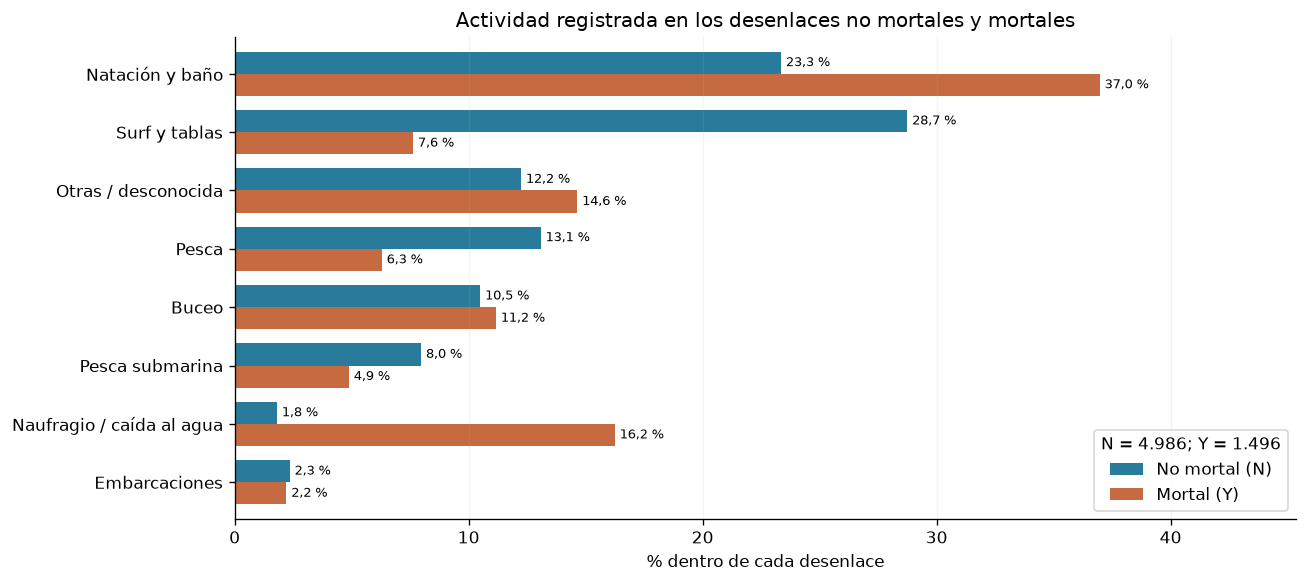

In [5]:
def outcome_distribution(data,column):
    counts=pd.crosstab(data[column],data['Fatal_clean']).reindex(columns=['N','Y'],fill_value=0)
    counts=counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
    pct=100*counts.div(counts.sum(axis=0).replace(0,np.nan),axis=1)
    return counts,pct

def distribution_table(counts,pct):
    table=counts.rename(columns={'N':'No mortales','Y':'Mortales'}).copy()
    table['% dentro de N']=pct['N']
    table['% dentro de Y']=pct['Y']
    table['Diferencia Y − N (pp)']=pct['Y']-pct['N']
    return table.round(2)

def comparison_plot(pct,title,denominators):
    ax=pct.rename(columns=LABELS).plot.barh(figsize=(11,max(4.6,len(pct)*.62)),
        color=[COLORS['N'],COLORS['Y']],width=.76)
    ax.invert_yaxis()
    for container in ax.containers:
        labels=[f'{v:.1f} %'.replace('.',',') for v in container.datavalues]
        ax.bar_label(container,labels=labels,padding=3,fontsize=8)
    ax.set(xlabel='% dentro de cada desenlace',ylabel='',title=title,
           xlim=(0,float(pct.max().max())*1.20+1))
    ax.legend(title=f'N = {num(denominators["N"])}; Y = {num(denominators["Y"])}',loc='lower right')
    ax.grid(axis='x',alpha=.15)
    plt.tight_layout()
    plt.show()

activity_counts,activity_pct=outcome_distribution(known,'actividad')
display(distribution_table(activity_counts,activity_pct))
comparison_plot(activity_pct,'Actividad registrada en los desenlaces no mortales y mortales',activity_counts.sum())
assert np.allclose(activity_pct.sum(axis=0),[100,100])
assert activity_counts.to_numpy().sum()==len(known)

### Complemento: desenlaces dentro de cada actividad
El denominador cambia a Y + N del grupo. UNKNOWN se cuenta aparte y **no se transforma en no mortal**. Los grupos pequeños o con muchos desconocidos requieren más cautela.

In [6]:
def outcome_summary(data,column):
    t=pd.crosstab(data[column],data['Fatal_clean']).reindex(columns=['N','Y','UNKNOWN'],fill_value=0)
    t['Conocidos']=t['N']+t['Y']
    t['% mortal entre conocidos']=100*t['Y']/t['Conocidos'].replace(0,np.nan)
    t['Total']=t[['N','Y','UNKNOWN']].sum(axis=1)
    t['% desconocido']=100*t['UNKNOWN']/t['Total'].replace(0,np.nan)
    return t.sort_values('Total',ascending=False)
activity_summary=outcome_summary(df,'actividad')
display(activity_summary.round(2))
assert activity_summary['Total'].sum()==len(df)

Fatal_clean,N,Y,UNKNOWN,Conocidos,% mortal entre conocidos,Total,% desconocido
actividad,,,,,,,
Natación y baño,1164,553,152,1717,32.21,1869,8.13
Surf y tablas,1433,114,62,1547,7.37,1609,3.85
Otras / desconocida,610,219,214,829,26.42,1043,20.52
Pesca,652,94,38,746,12.60,784,4.85
Buceo,523,167,70,690,24.20,760,9.21
Pesca submarina,397,73,38,470,15.53,508,7.48
Naufragio / caída al agua,90,243,54,333,72.97,387,13.95
Embarcaciones,117,33,15,150,22.00,165,9.09


## 6. Especies atribuidas según el desenlace
Esta comparación utiliza exclusivamente el subconjunto con desenlace conocido y especie atribuida. Cada columna porcentual suma 100 % sobre ese subconjunto, **no sobre todos los casos mortales o no mortales**. Un cero significa que no hay registros clasificados en esa combinación, no que esa especie sea incapaz de provocar un desenlace.

Fatal_clean,No mortales,Mortales,% dentro de N,% dentro de Y,Diferencia Y − N (pp)
especie,,,,,
Blanco,510,150,32.30,53.76,21.46
Tigre,198,69,12.54,24.73,12.19
Toro,187,37,11.84,13.26,1.42
Sand tiger / grey nurse,120,0,7.60,0.00,-7.60
Punta negra / spinner,89,0,5.64,0.00,-5.64
Arrecife,78,0,4.94,0.00,-4.94
Cobrizo / whaler,74,4,4.69,1.43,-3.25
Nodriza,71,0,4.50,0.00,-4.50
Mako,53,7,3.36,2.51,-0.85


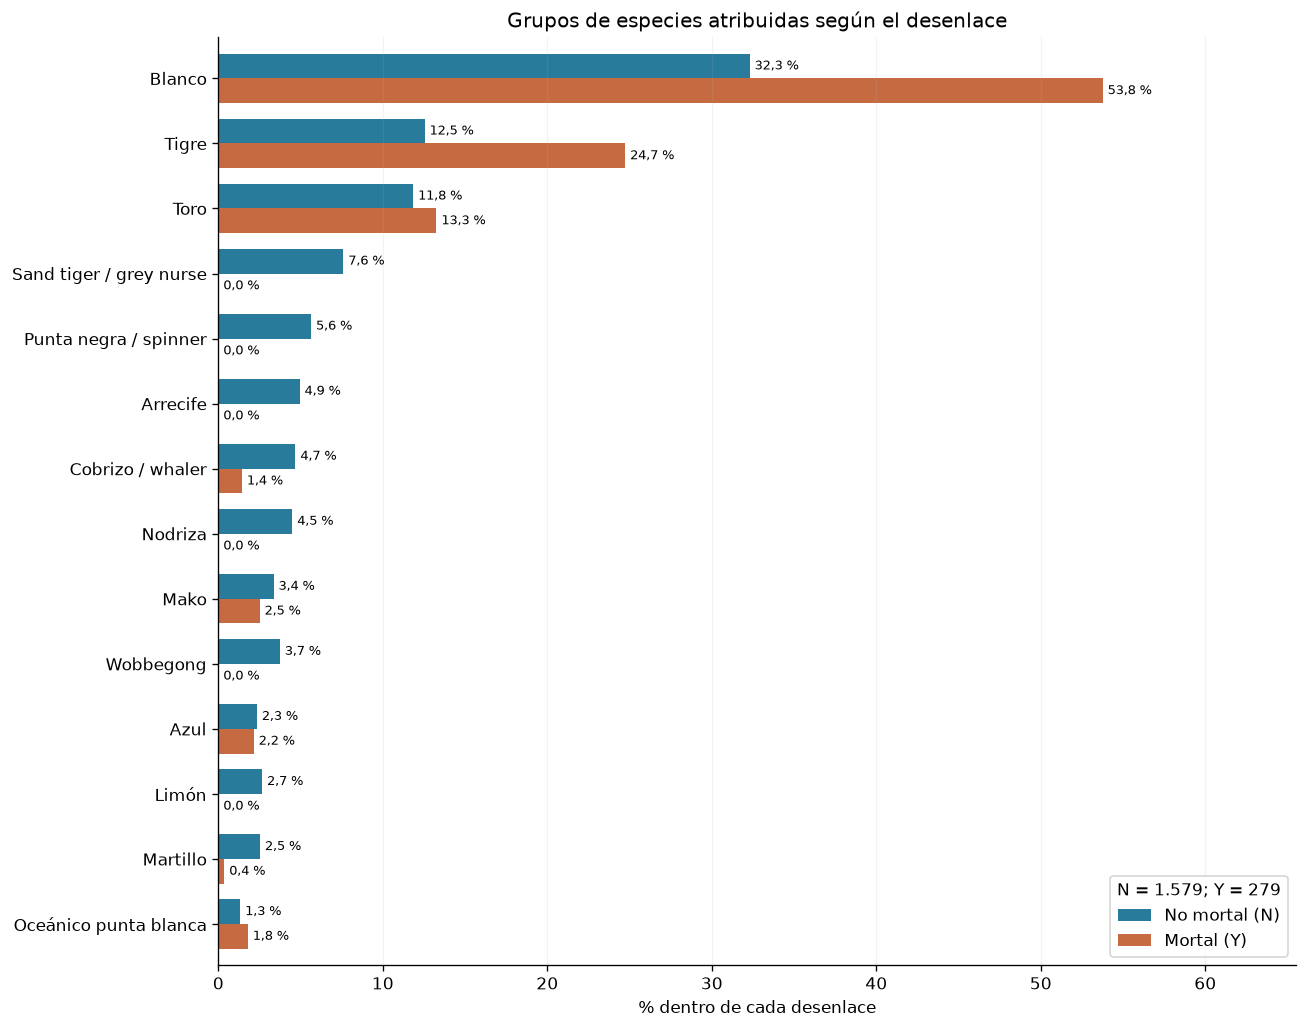

Complemento: desenlace dentro de cada grupo de especies atribuidas.


Fatal_clean,N,Y,UNKNOWN,Conocidos,% mortal entre conocidos,Total,% desconocido
especie,,,,,,,
Blanco,510,150,12,660,22.73,672,1.79
Tigre,198,69,5,267,25.84,272,1.84
Toro,187,37,3,224,16.52,227,1.32
Sand tiger / grey nurse,120,0,1,120,0.00,121,0.83
Punta negra / spinner,89,0,0,89,0.00,89,0.00
Arrecife,78,0,2,78,0.00,80,2.50
Cobrizo / whaler,74,4,1,78,5.13,79,1.27
Nodriza,71,0,0,71,0.00,71,0.00
Mako,53,7,0,60,11.67,60,0.00


In [7]:
species_counts,species_pct=outcome_distribution(ident,'especie')
display(distribution_table(species_counts,species_pct))
comparison_plot(species_pct,'Grupos de especies atribuidas según el desenlace',species_counts.sum())
species_summary=outcome_summary(df[df['especie'].ne('Sin identificar')],'especie')
print('Complemento: desenlace dentro de cada grupo de especies atribuidas.')
display(species_summary.round(2))
assert species_counts.to_numpy().sum()==len(ident)
assert np.allclose(species_pct.sum(axis=0),[100,100])

## 7. Contrastes exploratorios de asociación
Se usa χ² de Pearson y V de Cramér. El contraste de **actividad excluye “Otras / desconocida”**; su n difiere del gráfico. El contraste de especie usa todos los grupos atribuidos con Y/N: no se crea una categoría “Resto” que oculte una sola especie.

Se muestran n, grados de libertad, p, V, frecuencia esperada mínima y porcentaje de esperadas menores que 5. Los p son aproximaciones asintóticas. Se consideran diagnósticos orientativos —no garantías— que ninguna esperada sea menor que 1 y que como máximo el 20 % sean menores que 5.

No se interpretan etiquetas universales de fuerza para V. La heterogeneidad histórica, la selección de los registros y posibles dependencias limitan la inferencia. Un p pequeño no prueba causalidad ni importancia práctica. Estos contrastes son exploratorios y no sustituyen las tablas y sus denominadores.

In [8]:
def association(data,column):
    d=data[data['Fatal_clean'].isin(['N','Y'])].copy()
    excluded='Otras / desconocida' if column=='actividad' else 'Sin identificar'
    d=d[d[column].ne(excluded)]
    t=pd.crosstab(d[column],d['Fatal_clean']).reindex(columns=['N','Y'],fill_value=0)
    t=t.loc[t.sum(axis=1).gt(0)]
    if min(t.shape)<2 or t.sum(axis=0).eq(0).any():
        return {'Variable':column,'n':len(d),'p':np.nan,'V de Cramér':np.nan,'Diagnóstico':'No calculable'}
    chi,p,dof,e=chi2_contingency(t,correction=False)
    return {'Variable':column,'n':int(t.to_numpy().sum()),'χ²':chi,'gl':dof,'p':p,
        'V de Cramér':np.sqrt(chi/(t.to_numpy().sum()*min(t.shape[0]-1,t.shape[1]-1))),
        'Esperada mínima':e.min(),'% esperadas <5':100*(e<5).mean(),
        'Diagnóstico':'Sin alerta por esperadas' if e.min()>=1 and (e<5).mean()<=.2 else 'Cautela por esperadas'}

tests=pd.DataFrame([association(df,'actividad'),association(df,'especie')]).set_index('Variable')
display(tests)
small_species=species_counts.sum(axis=1).loc[lambda x:x<MIN_SPECIES_N]
print(f'Grupos con menos de {MIN_SPECIES_N} atribuciones Y/N (interpretación descriptiva cautelosa):')
display(small_species.to_frame('Registros Y/N'))

,n,χ²,gl,p,V de Cramér,Esperada mínima,% esperadas <5,Diagnóstico
Variable,,,,,,,,
actividad,5653,836.184593,6,2.335686e-177,0.384602,33.884663,0.000000,Sin alerta por esperadas
especie,1858,148.761188,13,3.661016e-25,0.282958,3.904198,3.571429,Sin alerta por esperadas


Grupos con menos de 30 atribuciones Y/N (interpretación descriptiva cautelosa):


,Registros Y/N
especie,
Oceánico punta blanca,26


## 8. Sensibilidad a los criterios y a la época
Se comprueban tres cuestiones distintas:
- **Invalid:** retirar esas filas permite aproximarse al filtro de la hipótesis 4, sin hacer idénticas las bases ni sus reglas.
- **Varios contextos:** retirar filas con coincidencia en más de un grupo de actividad permite comprobar la influencia de la prioridad. Es una población seleccionada diferente, no una corrección demostrada.
- **Época:** periodos anteriores a 1950, 1950–1999 y desde 2000, usando años enteros entre 1 y 2026. No se convierte a cero un año ausente. Los cortes son analíticos y no representan cambios causales.

Las comparaciones por periodo son descriptivas y no ajustan simultáneamente país, especie, exposición o notificación.

,Filas,N,Y,UNKNOWN,% mortal entre conocidos,Surf % dentro N,Baño % dentro Y
Población,,,,,,,
Todas las filas,7125,4986,1496,643,23.08,28.74,36.97
Sin Type=Invalid,6573,4969,1488,116,23.04,28.72,37.03
Sin actividad multicontexto,6646,4702,1344,600,22.23,29.20,40.03


,Población,Variable,n,χ²,gl,p,V de Cramér,Esperada mínima,% esperadas <5,Diagnóstico
0,Todas las filas,actividad,5653,836.184593,6,2.335686e-177,0.384602,33.884663,0.000000,Sin alerta por esperadas
1,Todas las filas,especie,1858,148.761188,13,3.661016e-25,0.282958,3.904198,3.571429,Sin alerta por esperadas
2,Sin Type=Invalid,actividad,5630,829.397794,6,6.840498e-176,0.383820,33.809947,0.000000,Sin alerta por esperadas
3,Sin Type=Invalid,especie,1857,148.923757,13,3.395255e-25,0.283189,3.906300,3.571429,Sin alerta por esperadas
4,Sin actividad multicontexto,actividad,5217,681.714782,6,5.422251e-144,0.361486,32.346176,0.000000,Sin alerta por esperadas


Registros Invalid por desenlace:


,Filas
Fatal_clean,
N,17
Y,8
UNKNOWN,527


Filas sin año utilizable: 131


Fatal_clean,N,Y,UNKNOWN
periodo,,,
Antes de 1950,788,701,199
1950–1999,1728,458,248
2000–2026,2404,276,192


,Periodo,Actividad,N,Y,Total N del periodo,Total Y del periodo,% dentro N,% dentro Y,Diferencia Y − N (pp)
0,Antes de 1950,Surf y tablas,23,7,788,701,2.92,1.00,-1.92
1,Antes de 1950,Natación y baño,262,311,788,701,33.25,44.37,11.12
2,Antes de 1950,Naufragio / caída al agua,47,167,788,701,5.96,23.82,17.86
3,1950–1999,Surf y tablas,434,38,1728,458,25.12,8.30,-16.82
4,1950–1999,Natación y baño,335,143,1728,458,19.39,31.22,11.84
5,1950–1999,Naufragio / caída al agua,35,52,1728,458,2.03,11.35,9.33
6,2000–2026,Surf y tablas,974,69,2404,276,40.52,25.00,-15.52
7,2000–2026,Natación y baño,553,79,2404,276,23.00,28.62,5.62
8,2000–2026,Naufragio / caída al agua,7,18,2404,276,0.29,6.52,6.23


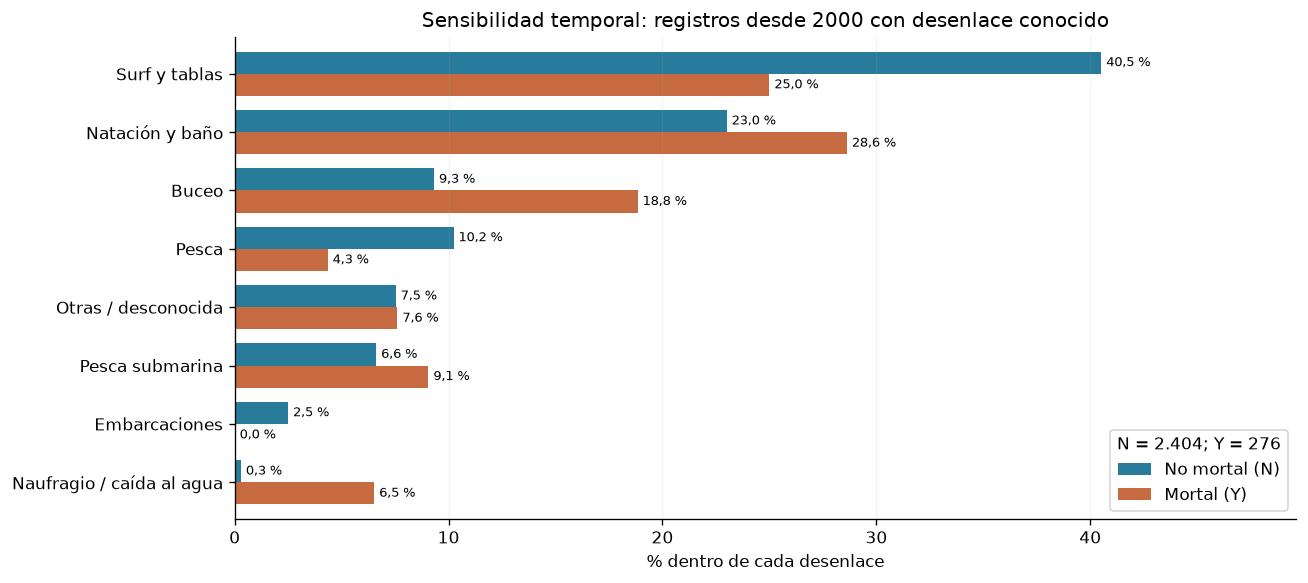

In [9]:
valid_mask=df['Type'].map(normalize).ne('invalid')
valid_df=df[valid_mask].copy()
scenarios={'Todas las filas':df,'Sin Type=Invalid':valid_df,
           'Sin actividad multicontexto':df[~df['actividad_multicontexto']]}
sensitivity=[]
for name,sub in scenarios.items():
    k=sub[sub['Fatal_clean'].isin(['N','Y'])]
    ac,ap=outcome_distribution(k,'actividad')
    sensitivity.append({'Población':name,'Filas':len(sub),'N':int(sub['Fatal_clean'].eq('N').sum()),
      'Y':int(sub['Fatal_clean'].eq('Y').sum()),'UNKNOWN':int(sub['Fatal_clean'].eq('UNKNOWN').sum()),
      '% mortal entre conocidos':100*k['Fatal_clean'].eq('Y').mean(),
      'Surf % dentro N':ap.loc['Surf y tablas','N'] if 'Surf y tablas' in ap.index else np.nan,
      'Baño % dentro Y':ap.loc['Natación y baño','Y'] if 'Natación y baño' in ap.index else np.nan})
sensitivity=pd.DataFrame(sensitivity).set_index('Población')
display(sensitivity.round(2))
sensitivity_tests=[]
for name,sub in scenarios.items():
    for col in ['actividad','especie']:
        # Retirar actividad multicontexto no se plantea como filtro de especie.
        if name=='Sin actividad multicontexto' and col=='especie':continue
        sensitivity_tests.append({'Población':name,**association(sub,col)})
display(pd.DataFrame(sensitivity_tests))
print('Registros Invalid por desenlace:')
display(df.loc[~valid_mask,'Fatal_clean'].value_counts().reindex(['N','Y','UNKNOWN'],fill_value=0).to_frame('Filas'))

period=pd.cut(df['Year_clean'],bins=[0,1949,1999,2026],labels=['Antes de 1950','1950–1999','2000–2026'])
df['periodo']=period
print(f'Filas sin año utilizable: {df["Year_clean"].isna().sum()}')
period_coverage=pd.crosstab(df['periodo'],df['Fatal_clean']).reindex(columns=['N','Y','UNKNOWN'],fill_value=0)
display(period_coverage)
period_rows=[]
for period_label in period.cat.categories:
    sub=df[df['periodo'].eq(period_label)]
    k=sub[sub['Fatal_clean'].isin(['N','Y'])]
    ac,ap=outcome_distribution(k,'actividad')
    for group in ['Surf y tablas','Natación y baño','Naufragio / caída al agua']:
        if group in ac.index:
            period_rows.append({'Periodo':period_label,'Actividad':group,'N':ac.loc[group,'N'],
             'Y':ac.loc[group,'Y'],'Total N del periodo':int(ac['N'].sum()),'Total Y del periodo':int(ac['Y'].sum()),
             '% dentro N':ap.loc[group,'N'],'% dentro Y':ap.loc[group,'Y'],
             'Diferencia Y − N (pp)':ap.loc[group,'Y']-ap.loc[group,'N']})
period_table=pd.DataFrame(period_rows)
display(period_table.round(2))
recent=df[df['Year_clean'].ge(2000)]
recent_known=recent[recent['Fatal_clean'].isin(['N','Y'])]
recent_counts,recent_pct=outcome_distribution(recent_known,'actividad')
comparison_plot(recent_pct,'Sensibilidad temporal: registros desde 2000 con desenlace conocido',recent_counts.sum())

## 9. Conclusiones y defensa oral
El texto siguiente se calcula con las tablas de esta ejecución. Las cifras pueden cambiar al usar la base unificada o revisar las atribuciones originales.

In [10]:
activity_diff=activity_pct['Y']-activity_pct['N']
species_diff=species_pct['Y']-species_pct['N']
major_negative=activity_diff.idxmin()
major_positive=activity_diff.idxmax()
rn=identified_by_outcome.loc['N','% con especie atribuida']
ry=identified_by_outcome.loc['Y','% con especie atribuida']
a_test=tests.loc['actividad']; s_test=tests.loc['especie']
invalid_row=sensitivity.loc['Sin Type=Invalid']
recent_leader_n=recent_pct['N'].idxmax(); recent_leader_y=recent_pct['Y'].idxmax()

text=f"""
### Respuesta a la pregunta
La hipótesis recibe **apoyo descriptivo en la base disponible**: los registros mortales y no mortales tienen composiciones diferentes de actividad y especie atribuida. Hay **{num(len(df))} filas**, **{num(len(known))} desenlaces conocidos** y **{num(df['Fatal_clean'].eq('UNKNOWN').sum())} desconocidos**.

**Actividades.**
- **{major_negative}** presenta la mayor diferencia negativa: {dec(activity_pct.loc[major_negative,'N'])} % dentro de N frente a {dec(activity_pct.loc[major_negative,'Y'])} % dentro de Y ({dec(abs(activity_diff[major_negative]))} puntos de diferencia).
- **Natación y baño** es el grupo más frecuente dentro de los mortales: {dec(activity_pct.loc['Natación y baño','Y'])} % de Y frente a {dec(activity_pct.loc['Natación y baño','N'])} % de N (+{dec(activity_diff['Natación y baño'])} puntos).
- **Naufragio / caída al agua** representa el {dec(activity_pct.loc['Naufragio / caída al agua','Y'])} % de Y y el {dec(activity_pct.loc['Naufragio / caída al agua','N'])} % de N. En la comparación complementaria, {dec(activity_summary.loc['Naufragio / caída al agua','% mortal entre conocidos'])} % de sus {num(activity_summary.loc['Naufragio / caída al agua','Conocidos'])} desenlaces conocidos son Y.
- El χ² de actividad utiliza **n = {num(a_test['n'])}**, excluyendo “Otras / desconocida”. V de Cramér = **{dec(a_test['V de Cramér'],3)}** y p = {a_test['p']:.3g}. Es una asociación de los registros, sin interpretación causal.

**Especies.**
- Se comparan **{num(len(ident))} casos** con desenlace conocido y especie atribuida. Blanco representa el **{dec(species_pct.loc['Blanco','Y'])} %** de Y frente al **{dec(species_pct.loc['Blanco','N'])} %** de N. Tigre representa el **{dec(species_pct.loc['Tigre','Y'])} %** de Y frente al **{dec(species_pct.loc['Tigre','N'])} %** de N.
- La cobertura difiere: **{dec(rn)} %** de los no mortales tienen especie atribuida ({num(species_counts['N'].sum())}/{num(coverage.loc['N','Registros'])}), frente al **{dec(ry)} %** de los mortales ({num(species_counts['Y'].sum())}/{num(coverage.loc['Y','Registros'])}). No conocemos la dirección ni la magnitud del posible sesgo resultante.
- V de Cramér = **{dec(s_test['V de Cramér'],3)}**, p = {s_test['p']:.3g}. La conclusión sobre especies es más limitada por la selección y la clasificación textual.

**Sensibilidad.**
- Sin Invalid quedan {num(invalid_row['Filas'])} filas y {num(invalid_row['UNKNOWN'])} UNKNOWN. El porcentaje mortal entre conocidos es {dec(invalid_row['% mortal entre conocidos'],2)} %, frente a {dec(sensitivity.loc['Todas las filas','% mortal entre conocidos'],2)} % en el conjunto. La tabla de contrastes permite comparar también las asociaciones. Esto no hace automáticamente equivalentes las bases del grupo.
- Desde 2000, con {num(len(recent_known))} desenlaces conocidos, predomina **{recent_leader_n}** dentro de N y **{recent_leader_y}** dentro de Y. La diferencia de natación/baño entre Y y N pasa de {dec(activity_diff['Natación y baño'])} puntos en el conjunto a {dec(recent_pct.loc['Natación y baño','Y']-recent_pct.loc['Natación y baño','N'])} desde 2000. La época cambia la magnitud de las diferencias y no queda controlada por esta estratificación descriptiva.

### Qué no demuestra
No se estima el riesgo real de un incidente o de morir por actividad o especie: faltan denominadores de exposición. Tampoco se ajustan simultáneamente país, época, circunstancias o notificación. Una especie ausente de una celda puede estar sin identificar en otras filas. Las filas no equivalen necesariamente a individuos independientes y un mismo suceso puede afectar a varias personas.

### Integración con el equipo
Las agrupaciones revisadas no reproducen exactamente las hipótesis 1 y 4. Antes de combinar porcentajes, los cuatro análisis deben usar la misma versión del archivo, decidir juntos el filtro Invalid y compartir reglas de actividad y especie. Las conclusiones presentes son reproducibles sobre el Excel identificado en la sección 1.

### Frase para la presentación
“En esta base histórica, el surf tiene más peso entre los registros no mortales y natación y naufragio entre los mortales. Entre las especies atribuidas, blanco y tigre pesan más en los mortales, pero falta la especie en la mayoría de esos casos. Son diferencias entre registros, no probabilidades de morir al realizar una actividad.”

### Aplicación al videojuego
Tres contextos pueden inspirar misiones: surf, baño/natación y naufragio/caída al agua. La incertidumbre sobre la especie puede convertirse en una mecánica de información incompleta. La dificultad, el rescate y las decisiones del personaje son propuestas creativas; los porcentajes históricos no se usan como probabilidades de muerte del jugador.
"""
display(Markdown(text))


### Respuesta a la pregunta
La hipótesis recibe **apoyo descriptivo en la base disponible**: los registros mortales y no mortales tienen composiciones diferentes de actividad y especie atribuida. Hay **7.125 filas**, **6.482 desenlaces conocidos** y **643 desconocidos**.

**Actividades.**
- **Surf y tablas** presenta la mayor diferencia negativa: 28,7 % dentro de N frente a 7,6 % dentro de Y (21,1 puntos de diferencia).
- **Natación y baño** es el grupo más frecuente dentro de los mortales: 37,0 % de Y frente a 23,3 % de N (+13,6 puntos).
- **Naufragio / caída al agua** representa el 16,2 % de Y y el 1,8 % de N. En la comparación complementaria, 73,0 % de sus 333 desenlaces conocidos son Y.
- El χ² de actividad utiliza **n = 5.653**, excluyendo “Otras / desconocida”. V de Cramér = **0,385** y p = 2.34e-177. Es una asociación de los registros, sin interpretación causal.

**Especies.**
- Se comparan **1.858 casos** con desenlace conocido y especie atribuida. Blanco representa el **53,8 %** de Y frente al **32,3 %** de N. Tigre representa el **24,7 %** de Y frente al **12,5 %** de N.
- La cobertura difiere: **31,7 %** de los no mortales tienen especie atribuida (1.579/4.986), frente al **18,6 %** de los mortales (279/1.496). No conocemos la dirección ni la magnitud del posible sesgo resultante.
- V de Cramér = **0,283**, p = 3.66e-25. La conclusión sobre especies es más limitada por la selección y la clasificación textual.

**Sensibilidad.**
- Sin Invalid quedan 6.573 filas y 116 UNKNOWN. El porcentaje mortal entre conocidos es 23,04 %, frente a 23,08 % en el conjunto. La tabla de contrastes permite comparar también las asociaciones. Esto no hace automáticamente equivalentes las bases del grupo.
- Desde 2000, con 2.680 desenlaces conocidos, predomina **Surf y tablas** dentro de N y **Natación y baño** dentro de Y. La diferencia de natación/baño entre Y y N pasa de 13,6 puntos en el conjunto a 5,6 desde 2000. La época cambia la magnitud de las diferencias y no queda controlada por esta estratificación descriptiva.

### Qué no demuestra
No se estima el riesgo real de un incidente o de morir por actividad o especie: faltan denominadores de exposición. Tampoco se ajustan simultáneamente país, época, circunstancias o notificación. Una especie ausente de una celda puede estar sin identificar en otras filas. Las filas no equivalen necesariamente a individuos independientes y un mismo suceso puede afectar a varias personas.

### Integración con el equipo
Las agrupaciones revisadas no reproducen exactamente las hipótesis 1 y 4. Antes de combinar porcentajes, los cuatro análisis deben usar la misma versión del archivo, decidir juntos el filtro Invalid y compartir reglas de actividad y especie. Las conclusiones presentes son reproducibles sobre el Excel identificado en la sección 1.

### Frase para la presentación
“En esta base histórica, el surf tiene más peso entre los registros no mortales y natación y naufragio entre los mortales. Entre las especies atribuidas, blanco y tigre pesan más en los mortales, pero falta la especie en la mayoría de esos casos. Son diferencias entre registros, no probabilidades de morir al realizar una actividad.”

### Aplicación al videojuego
Tres contextos pueden inspirar misiones: surf, baño/natación y naufragio/caída al agua. La incertidumbre sobre la especie puede convertirse en una mecánica de información incompleta. La dificultad, el rescate y las decisiones del personaje son propuestas creativas; los porcentajes históricos no se usan como probabilidades de muerte del jugador.


## 10. Comprobación final
Se verifican la integridad del archivo fuente, la preservación de los datos de entrada y la conciliación independiente de los recuentos. Las tablas y los gráficos permanecen guardados dentro del cuaderno.

In [11]:
assert df[raw.columns].equals(raw)
assert source.equals(raw.set_axis(source.columns,axis=1))
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==source_hash
assert int(coverage['Registros'].sum())==len(source)
assert activity_counts['N'].sum()==known['Fatal_clean'].eq('N').sum()
assert activity_counts['Y'].sum()==known['Fatal_clean'].eq('Y').sum()
assert species_counts['N'].sum()==((known['Fatal_clean']=='N') & known['especie'].ne('Sin identificar')).sum()
assert species_counts['Y'].sum()==((known['Fatal_clean']=='Y') & known['especie'].ne('Sin identificar')).sum()
assert tests.loc['actividad','n']==len(known[known['actividad'].ne('Otras / desconocida')])
assert tests.loc['especie','n']==len(ident)
print('Comprobaciones superadas: fuente intacta, originales conservados, denominadores y recuentos conciliados.')

Comprobaciones superadas: fuente intacta, originales conservados, denominadores y recuentos conciliados.
